# Workshop 11: Text sentiment with an RNN

**Real-life problem:** Triage product feedback: which reviews are complaints that support should see first?

**My twist:** Swap IMDB for business reviews: `tfds` `yelp_polarity_reviews` (it exists; `amazon_polarity` does not), using a subset to keep training fast. The lecturer's subword encoder no longer exists in current TensorFlow Datasets, so the input pipeline is rebuilt with Keras `TextVectorization`. Keep the BLSTM and stacked models, add a cheap TF-IDF + logistic regression baseline, and report per-class precision and recall.

**Done when:** Metrics for both models, the 10 most confident wrong predictions with your reading of why, and a sentence on how a team would use the output (e.g. route negatives to support).

*Baseline = the lecturer's workshop code (unmodified copy in `_baseline/`). It no longer runs on current TensorFlow, so Part A is a faithful port of it.*

---


## Part A: text classification with an RNN (the lecturer's baseline, ported)

The original notebook (TensorFlow's 2019 tutorial) loads IMDB reviews with a ready-made *subword encoder*. That encoder and the `subwords8k` dataset option have since been removed from TensorFlow Datasets, so the original fails at the first data cell. This is the same workshop rebuilt on today's tools, as close to the original as possible:

- **Text encoding:** Keras `TextVectorization` (whole words, top 10,000) replaces the subword encoder. Every review is cut or padded to 200 words.
- **Training:** 2 epochs instead of 10, and learning rate 1e-3 instead of 1e-4 to make up for it, so this part finishes in a few minutes on a laptop.
- **Unchanged:** the two models (one bidirectional LSTM; then two stacked), the IMDB data, and validating on the test set as the original did. That last one is a small leak; Part B does it properly.

In [1]:
import os, warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'          # hide TensorFlow's start-up messages
warnings.filterwarnings('ignore')                 # Keras warnings print file paths from your computer

import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
tf.get_logger().setLevel('ERROR')
tfds.disable_progress_bar()

def plot_graphs(history, string):
    plt.plot(history.history[string])
    plt.plot(history.history['val_' + string], '')
    plt.xlabel('Epochs'); plt.ylabel(string)
    plt.legend([string, 'val_' + string])
    plt.show()

In [2]:
dataset, info = tfds.load('imdb_reviews', with_info=True, as_supervised=True)   # downloads once (about 80 MB), then cached
train_dataset, test_dataset = dataset['train'], dataset['test']

train_texts = np.array([t.decode('utf-8', 'ignore') for t, _ in tfds.as_numpy(train_dataset)])
encoder = tf.keras.layers.TextVectorization(max_tokens=10000, output_sequence_length=200)
encoder.adapt(train_texts)
vocab = np.array(encoder.get_vocabulary())
print('Vocabulary size: {}'.format(len(vocab)))

Vocabulary size: 10000


In [3]:
# what the encoder does to a sentence
sample_string = 'Hello TensorFlow.'
encoded_string = encoder([sample_string]).numpy()[0]
print('Encoded string is {}'.format(encoded_string[:6]), '... (padded with zeros to 200)')
print('Decoded back: "{}"'.format(' '.join(vocab[encoded_string[encoded_string > 0]])))
# Unlike the old subword encoder, this is not reversible: it lowercases, drops punctuation and
# turns words it has not seen into [UNK]. The original notebook's `assert` would fail here.
for index in encoded_string[encoded_string > 0]:
    print('{} ----> {}'.format(index, vocab[index]))

Encoded string is [5010    1    0    0    0    0] ... (padded with zeros to 200)
Decoded back: "hello [UNK]"
5010 ----> hello
1 ----> [UNK]


In [4]:
BUFFER_SIZE, BATCH_SIZE = 10000, 64

def vectorise(text, label):
    return encoder(text), label

train_dataset = train_dataset.shuffle(BUFFER_SIZE, seed=0).batch(BATCH_SIZE).map(vectorise).prefetch(tf.data.AUTOTUNE)
test_dataset = test_dataset.batch(BATCH_SIZE).map(vectorise).prefetch(tf.data.AUTOTUNE)

def sample_predict(sentence, model):
    return float(model.predict(encoder([sentence]), verbose=0)[0][0])     # probability the review is positive

### One bidirectional LSTM

In [5]:
tf.keras.utils.set_random_seed(0)
model = tf.keras.Sequential([
    tf.keras.Input(shape=(200,)),
    tf.keras.layers.Embedding(len(vocab), 64),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])
model.compile(loss='binary_crossentropy', optimizer=tf.keras.optimizers.Adam(1e-3), metrics=['accuracy'])
history = model.fit(train_dataset, epochs=2, validation_data=test_dataset, validation_steps=30, verbose=2)

test_loss, test_acc = model.evaluate(test_dataset, verbose=0)
print('Test Loss: {:.3f}'.format(test_loss))
print('Test Accuracy: {:.3f}'.format(test_acc))

Epoch 1/2
391/391 - 50s - 127ms/step - accuracy: 0.7678 - loss: 0.4706 - val_accuracy: 0.8172 - val_loss: 0.4108
Epoch 2/2
391/391 - 55s - 140ms/step - accuracy: 0.8902 - loss: 0.2822 - val_accuracy: 0.8380 - val_loss: 0.3618
Test Loss: 0.372
Test Accuracy: 0.835


positive example -> 0.781
negative example -> 0.106


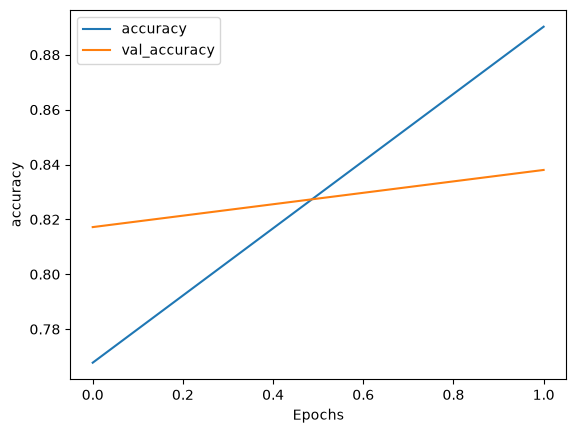

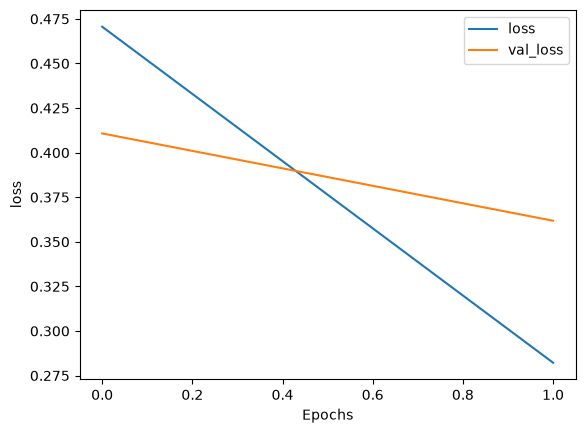

In [6]:
sample_pred_text = ('The movie was cool. The animation and the graphics '
                    'were out of this world. I would recommend this movie.')
print('positive example ->', round(sample_predict(sample_pred_text, model), 3))
print('negative example ->', round(sample_predict('A boring, badly acted film. I want my two hours back.', model), 3))
plot_graphs(history, 'accuracy')
plot_graphs(history, 'loss')

### Two stacked LSTM layers

Epoch 1/2
391/391 - 80s - 205ms/step - accuracy: 0.7035 - loss: 0.5662 - val_accuracy: 0.8083 - val_loss: 0.4314
Epoch 2/2
391/391 - 87s - 221ms/step - accuracy: 0.8704 - loss: 0.3277 - val_accuracy: 0.8458 - val_loss: 0.3608
Test Loss: 0.359
Test Accuracy: 0.845
positive example -> 0.666


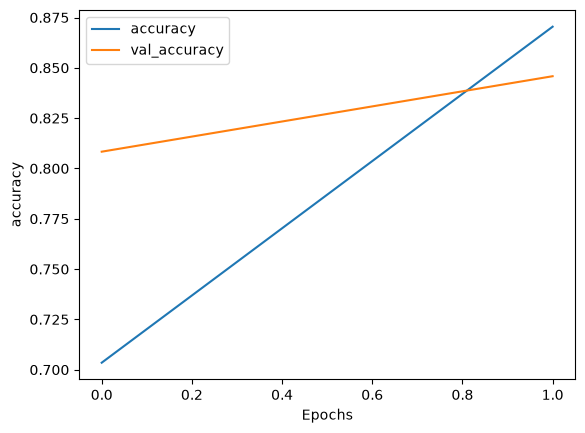

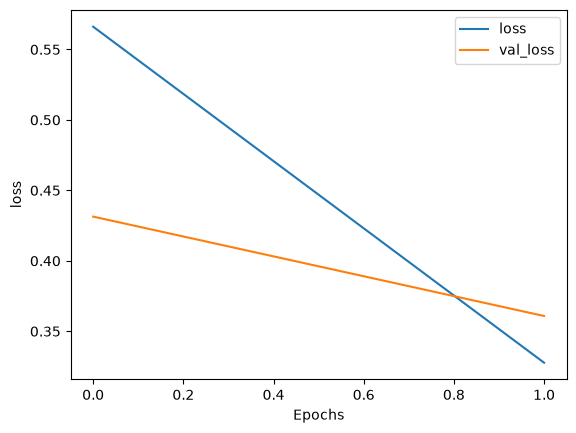

In [7]:
tf.keras.utils.set_random_seed(0)
model = tf.keras.Sequential([
    tf.keras.Input(shape=(200,)),
    tf.keras.layers.Embedding(len(vocab), 64),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64, return_sequences=True)),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1, activation='sigmoid')
])
model.compile(loss='binary_crossentropy', optimizer=tf.keras.optimizers.Adam(1e-3), metrics=['accuracy'])
history = model.fit(train_dataset, epochs=2, validation_data=test_dataset, validation_steps=30, verbose=2)

test_loss, test_acc = model.evaluate(test_dataset, verbose=0)
print('Test Loss: {:.3f}'.format(test_loss))
print('Test Accuracy: {:.3f}'.format(test_acc))
print('positive example ->', round(sample_predict(sample_pred_text, model), 3))
plot_graphs(history, 'accuracy')
plot_graphs(history, 'loss')

---
## Part B: real life: which reviews should support see first?

**Problem:** a business gets far more reviews than anyone can read. If a model can spot the unhappy ones, a support team could reply to complaints first. **Which model should do the sorting, and how many complaints would it catch?**

**Data:** Yelp business reviews (TensorFlow Datasets `yelp_polarity_reviews`). According to the dataset's own description, 1 and 2 star reviews are labelled negative and **3 and 4 star reviews positive**, so a lukewarm 3-star review counts as "positive". That matters later. I use a fixed random sample of **20,000 reviews to train, 2,000 to tune, 5,000 to test**, so every model sees exactly the same data and the notebook runs in minutes.

**Models:** the lecturer's two LSTMs (same as Part A, with early stopping on the tuning set), and a cheap baseline that only counts words and word pairs: **TF-IDF + logistic regression**. Here the class that matters is **negative = complaint**.

In [8]:
import os, warnings, time
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import tensorflow as tf
import tensorflow_datasets as tfds
import keras
from keras import layers
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score

tf.get_logger().setLevel('ERROR'); tfds.disable_progress_bar()
yelp = tfds.load('yelp_polarity_reviews', as_supervised=True)             # downloads once (about 160 MB), then cached
keras.utils.set_random_seed(0)            # same sample every time, whether or not Part A ran first

def sample(split, n, seed=0):
    texts, labels = [], []
    for t, l in tfds.as_numpy(split.shuffle(100_000, seed=seed, reshuffle_each_iteration=False).take(n)):
        texts.append(t.decode('utf-8', 'ignore')); labels.append(int(l))
    return np.array(texts, dtype=object), np.array(labels)

X_all, y_all = sample(yelp['train'], 22_000)
X_train, y_train, X_val, y_val = X_all[:20_000], y_all[:20_000], X_all[20_000:], y_all[20_000:]
X_test, y_test = sample(yelp['test'], 5_000)
words = np.array([len(t.split()) for t in X_train])
print(f'train {len(X_train):,} | tune {len(X_val):,} | test {len(X_test):,} | share negative in test: {(y_test == 0).mean() * 100:.0f}%')
print(f'review length: median {np.median(words):.0f} words, 90th percentile {np.percentile(words, 90):.0f}')

train 20,000 | tune 2,000 | test 5,000 | share negative in test: 50%
review length: median 98 words, 90th percentile 281


In [9]:
results, proba = {}, {}

def score(name, p_positive, seconds, n_params):
    pred = (p_positive >= 0.5).astype(int)
    proba[name] = p_positive
    results[name] = {'accuracy (%)': accuracy_score(y_test, pred) * 100,
                     'complaints caught (negative recall, %)': recall_score(y_test, pred, pos_label=0) * 100,
                     'flagged that are complaints (negative precision, %)': precision_score(y_test, pred, pos_label=0) * 100,
                     'positive recall (%)': recall_score(y_test, pred) * 100,
                     'positive precision (%)': precision_score(y_test, pred) * 100,
                     'training time (s)': seconds, 'parameters': n_params}

# 1) the cheap baseline: count words and word pairs, weight them by how informative they are, fit a straight line
t0 = time.time()
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=100_000, sublinear_tf=True)
logreg = LogisticRegression(max_iter=2000, C=4).fit(tfidf.fit_transform(X_train), y_train)
score('TF-IDF + logistic regression', logreg.predict_proba(tfidf.transform(X_test))[:, 1], time.time() - t0, logreg.coef_.size + 1)

In [10]:
# 2) and 3) the lecturer's two LSTMs, trained on the same reviews
yelp_encoder = layers.TextVectorization(max_tokens=20_000, output_sequence_length=200)
yelp_encoder.adapt(X_train)

def batches(X, y, shuffle=False):
    d = tf.data.Dataset.from_tensor_slices((X.astype(str), y))
    if shuffle: d = d.shuffle(len(X), seed=0)
    return d.batch(64).map(lambda t, l: (yelp_encoder(t), l)).prefetch(tf.data.AUTOTUNE)

train_b, val_b, test_b = batches(X_train, y_train, shuffle=True), batches(X_val, y_val), batches(X_test, y_test)

def lstm(stacked):
    body = ([layers.Bidirectional(layers.LSTM(64, return_sequences=True)), layers.Bidirectional(layers.LSTM(32)),
             layers.Dense(64, activation='relu'), layers.Dropout(0.5)] if stacked else
            [layers.Bidirectional(layers.LSTM(64)), layers.Dense(64, activation='relu')])
    return keras.Sequential([keras.Input(shape=(200,)), layers.Embedding(20_000, 64)] + body + [layers.Dense(1, activation='sigmoid')])

for name, stacked in [('BLSTM (lecturer)', False), ('stacked BLSTM (lecturer)', True)]:
    keras.utils.set_random_seed(0)
    net = lstm(stacked)
    net.compile(loss='binary_crossentropy', optimizer=keras.optimizers.Adam(1e-3), metrics=['accuracy'])
    t0 = time.time()
    net.fit(train_b, validation_data=val_b, epochs=3, verbose=2,
            callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=1, restore_best_weights=True)])
    score(name, net.predict(test_b, verbose=0).ravel(), time.time() - t0, net.count_params())

Epoch 1/3
313/313 - 39s - 126ms/step - accuracy: 0.8126 - loss: 0.4083 - val_accuracy: 0.8760 - val_loss: 0.2883
Epoch 2/3
313/313 - 42s - 135ms/step - accuracy: 0.9261 - loss: 0.2027 - val_accuracy: 0.8870 - val_loss: 0.2783
Epoch 3/3
313/313 - 43s - 136ms/step - accuracy: 0.9493 - loss: 0.1453 - val_accuracy: 0.8900 - val_loss: 0.3189
Epoch 1/3
313/313 - 64s - 203ms/step - accuracy: 0.8059 - loss: 0.4257 - val_accuracy: 0.8960 - val_loss: 0.2942
Epoch 2/3
313/313 - 71s - 226ms/step - accuracy: 0.9269 - loss: 0.2100 - val_accuracy: 0.8900 - val_loss: 0.3023


### 1. Which model?

In [11]:
table = pd.DataFrame(results).T
table['training time (s)'] = table['training time (s)'].round(0).astype(int)
table['parameters'] = table['parameters'].astype(int)
table.round(1)

,accuracy (%),"complaints caught (negative recall, %)","flagged that are complaints (negative precision, %)",positive recall (%),positive precision (%),training time (s),parameters
TF-IDF + logistic regression,93.5,93.8,93.2,93.2,93.8,5,100001
BLSTM (lecturer),89.6,87.1,91.6,92.0,87.8,126,1354369
stacked BLSTM (lecturer),90.0,89.4,90.4,90.5,89.6,138,1391489


- **The cheap model wins.** TF-IDF + logistic regression gets 93.5% accuracy and catches 93.8% of complaints. The lecturer's BLSTM gets 89.6% and catches 87.1%; the stacked BLSTM 90.0% and 89.4%.
- **And it is far cheaper:** about 5 seconds to train against about 2 minutes, and 100,000 numbers (one weight per word or word pair) against about 1.4 million.
- **Fair caveat:** LSTMs usually need much more data and tuning than 20,000 reviews and three epochs; trained on the full 560,000 reviews they might close the gap or overtake (not tested here). The product question is whether a few points are worth the extra cost and opacity. Same lesson as workshop 5: start with the simple model.

### 2. What would the support team actually get?
Using the best model. Instead of the default 50% line, a team can choose how sure the model must be before a review is routed to them. Higher bar: fewer reviews to read, but more complaints missed.

In [12]:
best = table['accuracy (%)'].idxmax()
p_negative = 1 - proba[best]
rows = []
for bar in (0.5, 0.7, 0.9):
    routed = p_negative >= bar
    rows.append({'route if P(complaint) is at least': bar,
                 'reviews routed (%)': routed.mean() * 100,
                 'of those, real complaints (%)': (y_test[routed] == 0).mean() * 100,
                 'complaints caught (%)': routed[y_test == 0].mean() * 100,
                 'complaints missed (per 1,000 reviews)': ((~routed) & (y_test == 0)).sum() / len(y_test) * 1000})
print('best model:', best)
pd.DataFrame(rows).set_index('route if P(complaint) is at least').round(1)

best model: TF-IDF + logistic regression


,reviews routed (%),"of those, real complaints (%)",complaints caught (%),"complaints missed (per 1,000 reviews)"
route if P(complaint) is at least,,,,
0.5,50.3,93.2,93.8,30.8
0.7,43.7,97.3,85.0,74.8
0.9,30.2,99.1,59.8,200.6


- **At the default line (50%)** support would read about half of all reviews (50.3%). 93% of what they read are real complaints, and 94% of complaints are caught, so about 31 complaints in every 1,000 reviews slip through.
- **Raising the bar to 70%** cuts the reading to 44% of reviews and makes 97% of them real complaints, but catches only 85% of complaints (about 75 missed per 1,000).
- **At 90%** the inbox is almost pure complaints (99%), but 40% of complaints are missed (about 200 per 1,000).
- The right line depends on how many reviews the team can read and how costly an unanswered complaint is. It is the same trade-off as the fraud alert line in workshop 3-2.

### 3. The ten most confident mistakes
Where the best model was most sure, and wrong. Reading these is the quickest way to see what a model doesn't understand.

In [13]:
pd.set_option('display.max_colwidth', 320)
pred = (proba[best] >= 0.5).astype(int)
wrong = np.where(pred != y_test)[0]
confidence = np.abs(proba[best][wrong] - 0.5)
top = wrong[np.argsort(-confidence)][:10]
pd.DataFrame({'true label': np.where(y_test[top] == 0, 'complaint', 'positive'),
              'P(positive)': proba[best][top].round(3),
              'review (first 300 characters)': [t[:300].replace('\n', ' ') for t in X_test[top]]})

,true label,P(positive),review (first 300 characters)
0,complaint,0.995,"I had both a red tinga as well as a chili verde gordita. I also enjoyed a large cup of the best Horchata in Las Vegas. Fresh and warm, the gorditas were filling and good.....but not great. Good for a quick stop, but there are much better options when looking for a full flavored, spicy, authentic gor"
1,positive,0.020,"This place is so much better since they changed owners.\n\nMy wife and I went when it was the old owners, it was terrible. We waited forever and the food never came before we walked out. People were served before us that walked in after and my wife actually got her soup before me and I sat and wai"
2,positive,0.021,"Soooooo good but server was eh. Something we ordered came with marinated olives and I didn't know, so when I ordered olives, she should have said something. BTW, they come warm. I'm not used to that. I prefer cold."
3,complaint,0.964,"We eat here from time to time. It is good enough that we go back, but not my favorite. My husband thinks it is great."
4,positive,0.036,"Perhaps my expectations were too high because of all the hype I'd heard, but I have to say I was a little disappointed. We did a girls' night out and were so excited about this new great wine/chocolate combo thing, but after waiting forever for a table we waited forever for a waitress, who utimately"
5,complaint,0.956,"The food is excellent. Plenty of options from big burgers to salads and everything in between. The two female bartenders are attentive, nice, and bust their humps to make sure everyone in their service is happy. However, I have never had good service anywhere but at the bar. Not once. The wait-"
6,positive,0.045,"I\""""m really bummed as I drove by today and like the previous poster in April said, the store front is empty and I called the place and the phone has been disconnected. Feeling sad another small business gone."
7,complaint,0.954,Thank you for all the emails you sent me on my review! I was surprised at how many responses I recieved from people searching for the right dentist..\nI shared my new dentist information and even got some movie tickets from my dentist for the referrals!\nI find it funny how since I wrote this review
8,complaint,0.952,"Get the concrete mixer, you'll love it!\n\nOther than that, it's fast food."
9,complaint,0.948,"Food...BOMB! Everything they do in the kitchen, they do right.\nMusic is good and usually pretty loud..\nBring a group of people and sit at the bar. This is where you'll get served the fastest..servers make themselves scarce and don't talk much.\n It's worth a trip, for fried pickles!"


**My reading of the ten mistakes** (row numbers as in the table):
- **Mixed reviews (rows 0, 5, 8, 9):** praise and complaint in the same review. The model adds up words, so "best", "fresh", "love it" and "BOMB" outweigh a verdict hidden in "but not great", "however... never had good service" or "other than that, it's fast food". It can't tell which part is the conclusion.
- **Negative words about something else (rows 1 and 6):** the bad experience was with the *old* owners, and the sadness is about the place closing down. The reviewer is happy (or a fan); the words are not.
- **Sarcasm and missing context (row 7):** a cheerful follow-up to an earlier bad review of a dentist ("They must have a lot of friends and family!"). Without the earlier review it reads as praise.
- **Borderline labels (rows 2, 3 and 4):** this dataset counts 3-star reviews as positive and 2-star as negative, so "a little disappointed... head there for drinks but not for food" is labelled *positive* and "good enough that we go back" is labelled *complaint*. A person reading only the text would make the same "mistakes".

So about six of the ten errors are about understanding (contrast, time, sarcasm) and the rest are about where the line between 2 and 3 stars falls.

### Verdict, and how a team would use it
**Use the simple model.** TF-IDF + logistic regression sorts Yelp reviews into complaints and praise with 93.5% accuracy, catching 94% of complaints, and trains in seconds. The lecturer's LSTMs were 3 to 4 points worse and 20 to 30 times slower to train on the same data.

**How a support team would use it:** send every review the model scores at least 70% likely to be a complaint straight to support (about 44% of reviews, 97% of them real complaints), and have a person skim the uncertain middle (scores between 30% and 70%), because that is where the mixed reviews and sarcasm sit.

**Caveats:** the labels come from star ratings, not from what people wrote, and this dataset counts 3-star reviews as positive, so lukewarm reviews a real support team would want to see are labelled "not a complaint"; one sample of 20,000 training reviews; the LSTMs were given little data and no tuning; and with 5,000 test reviews, accuracy is only accurate to about ±0.7 points.